# Comparing strategies

How a sample is shrunk changes its species-area curve. This notebook runs several strategies on one sample, compares their fits, and places them against random nests.

In [1]:
import matplotlib.pyplot as plt

import samplesar

plt.rcParams["figure.dpi"] = 80

In [2]:
sample = samplesar.sources.simulated(n_points=300, seed=2).merge_within(20)
sample

Sample(n_observations=630, n_points=300, n_species=40, area=6009.94)

## The strategies

Every strategy is a function in `samplesar.strategies`, and can be run by name.

In [3]:
for name, what in samplesar.strategies.available().items():
    print(f"{name:18} {what}")

random             Nest a sample by removing one point at a time, uniformly at random.
order              Nest a sample by removing its points in a given order.
hull_random        Nest a sample by removing a random vertex of its convex hull at each step.
hull_weighted      Nest a sample by removing a random hull vertex, weighted by its isolation.
hull_peel          Nest a sample by peeling off its whole convex hull at each step.
grid_peel          Nest a sample by peeling the convex layers of its occupied grid cells.
hull_area          Nest a sample by removing the hull vertex that changes its area least or most.
hull_masked_area   Nest a sample by removing the hull vertex that changes its area within the mask least or most.
hull_species       Nest a sample by removing the hull vertex that loses the fewest or most species.
hull_distance      Nest a sample by removing the hull vertex farthest from, or closest to, its center.
concave_peel       Nest a sample by peeling off its concave hu

In [4]:
nests = {
    "hull_peel": samplesar.strategies.hull_peel(sample),
    "radial": samplesar.strategies.radial(sample),
    "density_peel": samplesar.strategies.density_peel(sample),
    "hull_species (keep most)": samplesar.strategies.hull_species(sample, keep="most"),
    "hull_rarity (rare first)": samplesar.strategies.hull_rarity(sample, remove="rare"),
    "random": samplesar.strategies.random(sample, seed=0),
}
table = samplesar.evaluate.compare(nests, model="power")
table[["n_steps", "c", "z", "r_squared"]].round(3)

,n_steps,c,z,r_squared
nest,,,,
hull_peel,23,0.928,0.446,0.965
radial,298,0.995,0.442,0.947
density_peel,298,1.527,0.383,0.989
hull_species (keep most),298,3.379,0.301,0.862
hull_rarity (rare first),298,0.239,0.592,0.985
random,298,0.048,0.768,0.938


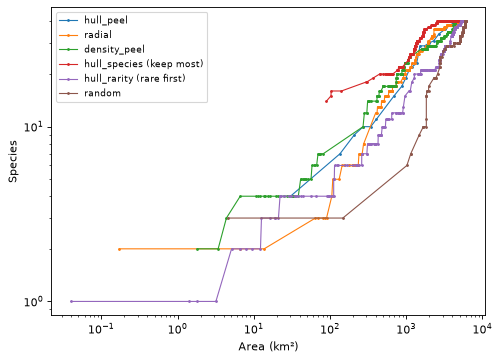

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, nest in nests.items():
    data = nest.sar_data()
    ax.plot(data["area"], data["species"], marker=".", markersize=3, linewidth=1, label=name)
ax.set(xscale="log", yscale="log", xlabel="Area (km²)", ylabel="Species")
ax.legend(fontsize=8);

The strategies that look at species pull the curve apart: keeping the most species at each step flattens it, and removing the rarest first steepens it. Removing points at random barely shrinks the hull while species fall, which gives a steep curve that says little about area.

## Against a random baseline

Steps of one nest share most of their points, so one nest's R² isn't independent evidence. A fairer question is where a strategy's fit falls among many random nests of the same sample.

In [6]:
baseline = samplesar.evaluate.baseline(sample, n=49, strategy="hull_random")
samplesar.evaluate.against_baseline(nests["hull_rarity (rare first)"], baseline).round(3)

,value,mean,sd,q025,q975,n,p
c,0.239,0.926,0.107,0.751,1.108,49,0.02
z,0.592,0.448,0.014,0.425,0.473,49,0.02
r_squared,0.985,0.968,0.008,0.951,0.981,49,0.06


## One curve from many random nests

`ensemble` reads many random nests at the same areas: the strategy's expected curve, and the band a single nest falls in.

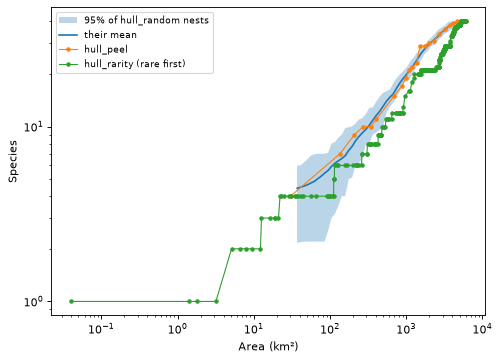

In [7]:
band = samplesar.evaluate.ensemble(sample, "hull_random", n=49)

fig, ax = plt.subplots(figsize=(7, 5))
ax.fill_between(band["area"], band["q025"], band["q975"], alpha=0.3, label="95% of hull_random nests")
ax.plot(band["area"], band["mean"], label="their mean")
for name in ("hull_peel", "hull_rarity (rare first)"):
    data = nests[name].sar_data()
    ax.plot(data["area"], data["species"], marker=".", linewidth=1, label=name)
ax.set(xscale="log", yscale="log", xlabel="Area (km²)", ylabel="Species")
ax.legend(fontsize=8);

## How much a fit owes to the points sampled

A deterministic strategy gives one nest per sample. `bootstrap` resamples the points, nests each resample and fits it.

In [8]:
fits = samplesar.evaluate.bootstrap(sample, "hull_peel", n=49)
fits["z"].quantile([0.025, 0.5, 0.975]).round(3)

0.025    0.407
0.500    0.448
0.975    0.479
Name: z, dtype: float64

## Elevation and time

The simulated observations carry an elevation and a date, as GBIF records do, so the sample can also be shrunk from the summits down, from the valleys up, or back through time. Read these as diagnostics, not as the region's $z$: removing the summits first leaves the valleys' hull almost whole, so species fall while area barely moves.

In [9]:
more = {
    "from the summits down": samplesar.strategies.elevation(sample, remove="highest"),
    "from the valleys up": samplesar.strategies.elevation(sample, remove="lowest"),
    "back through time": samplesar.strategies.temporal(sample),
}
samplesar.evaluate.compare(more)[["n_steps", "z", "r_squared"]].round(3)

,n_steps,z,r_squared
nest,,,
from the summits down,298,2.017,0.905
from the valleys up,298,0.483,0.951
back through time,298,0.615,0.939


## Several patches at once

One hull around separate clusters spans the empty ground between them. `split` nests the clusters as separate patches, and the areas are those of the patches' hulls together.

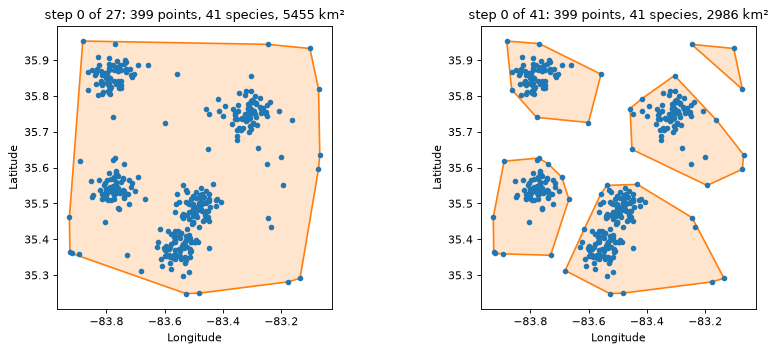

In [10]:
piled = samplesar.sources.simulated(n_points=400, clustered=0.9, seed=5).merge_within(20)
patches = samplesar.strategies.split(piled, "hull_peel", parts=5, seed=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
samplesar.plot.nest(samplesar.strategies.hull_peel(piled), ax=axes[0])
samplesar.plot.nest(patches, ax=axes[1])
fig.tight_layout()